# 🌀 Optical Rotatory Dispersion & The Barber Pole Effect
**Author / Presenter:** Kartik Khare  
**Course / Project:** Advanced Physical Optics & Computational Electrodynamics  
**GitHub Repository:** [github.com/thisiskartik05/Optimism](https://github.com/thisiskartik05/Optimism)  

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/thisiskartik05/Optimism/blob/main/barber_pole_simulation.ipynb)

---

> **Zero Local Installation Required:**  
> Click the **Open in Colab** badge above to launch, execute, and present this interactive 3D simulation directly in your web browser with free cloud resources. No software downloads or local device setup are required.


In [1]:
# ===========================================================================
# 1. Environment & Dependency Configuration
# ===========================================================================
# Automatically verifies and installs dependencies in Google Colab / JupyterLab
import sys
import os

required_pkgs = ['numpy', 'matplotlib', 'ipywidgets', 'plotly']
missing_pkgs = []

for pkg in required_pkgs:
    try:
        __import__(pkg)
    except ImportError:
        missing_pkgs.append(pkg)

if missing_pkgs:
    print(f"Installing missing presentation packages: {missing_pkgs}...")
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + missing_pkgs)
    print("✓ All dependencies installed successfully!")

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, HTML
import ipywidgets as widgets

# Configure high-DPI matplotlib presentation styling
%matplotlib inline
plt.rcParams['figure.dpi'] = 140
plt.rcParams['figure.autolayout'] = True
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#444444'
plt.rcParams['axes.linewidth'] = 0.8

print("✓ Core libraries loaded. Environment ready for physical optics simulation.")


✓ Core libraries loaded. Environment ready for physical optics simulation.


---
## 2. Theoretical Framework

### 2.1 Molecular Chirality & Circular Birefringence
When linearly polarized light propagates through an isotropic chiral medium (such as an aqueous solution of D-sucrose), the absence of inversion symmetry causes left-circularly ($L$) and right-circularly ($R$) polarized states to experience distinct effective refractive indices:
$$n_L \neq n_R$$

A linearly polarized plane wave with electric field amplitude $E_0$ polarized at angle $\theta_0$ can be decomposed into equal amplitudes of opposite circular polarization:
$$\vec{E}(z) = \frac{E_0}{\sqrt{2}} \left( \hat{e}_R e^{i(k_R z - \omega t)} + \hat{e}_L e^{i(k_L z - \omega t)} \right)$$

where $k_R = \frac{2\pi n_R}{\lambda}$ and $k_L = \frac{2\pi n_L}{\lambda}$. After propagating an axial distance $z$, the relative phase delay is:
$$\Delta\phi = (k_L - k_R)z = \frac{2\pi}{\lambda}(n_L - n_R)z$$

Recombining the circular components yields a linearly polarized wave whose plane of polarization has rotated by an angle $\theta(z)$:
$$\theta(z) = \frac{\Delta\phi}{2} = \frac{\pi}{\lambda}(n_L - n_R)z$$

---

### 2.2 Cauchy's Optical Rotatory Dispersion (ORD)
The circular birefringence $(n_L - n_R)$ exhibits chromatic dispersion. According to Cauchy's dispersion approximation, the specific rotation $\alpha(\lambda)$ varies inversely with the square of the wavelength:
$$\alpha(\lambda) \approx \frac{A}{\lambda^2}$$

For a solution of concentration $c$ (mol/L or g/mL) and optical path length $z$, the net polarization angle becomes:
$$\theta(z, \lambda) = \theta_0 + \left( \frac{A}{\lambda^2} \right) \cdot c \cdot z$$

Because blue light ($\lambda \approx 450\text{ nm}$) has a much shorter wavelength than red light ($\lambda \approx 650\text{ nm}$), its rotation rate is substantially greater:
$$\frac{\theta_{\text{Blue}}}{\theta_{\text{Red}}} \approx \left(\frac{650}{450}\right)^2 \approx 2.08$$

---

### 2.3 Rayleigh Dipole Scattering as an Internal Polarimeter
Why do we observe colors when looking at the cylinder from the side?
Sugar molecules and microscopic scattering centers act as oscillating Rayleigh dipoles driven by the local electric field $\vec{E}(z)$. An electric dipole with moment $\vec{p} \parallel \vec{E}$ emits electromagnetic radiation with an angular distribution:
$$\frac{dP}{d\Omega} \propto \sin^2\psi$$
where $\psi$ is the angle between the dipole axis $\vec{p}$ and the observer's line-of-sight unit vector $\hat{v}$.
* If the dipole oscillates directly toward the observer ($\psi = 0$), **zero scattered intensity** is observed.
* If the dipole oscillates perpendicular to the line of sight ($\psi = 90^\circ$), **maximum scattered intensity** is observed.

When observing perpendicular to the cylinder axis along the $y$-direction ($\hat{v} = \hat{y}$), the intensity of scattered light with polarization angle $\theta(z, \lambda)$ is governed by:
$$I(\lambda, z) \propto \cos^2(\theta(z, \lambda) - \phi_{view})$$

---

### 2.4 Cylindrical Geometry Integration: Formation of the Barber Pole Stripes
Why do the bands appear **diagonal** instead of horizontal?
In a cylindrical column of radius $R$, a lateral line-of-sight at horizontal offset $x \in [-R, R]$ traverses a chord through the fluid of total length:
$$L(x) = 2\sqrt{R^2 - x^2}$$

A full volumetric simulation accounts for:
1. **Varying optical path length:** Center rays penetrate a depth of $2R$, while edge rays penetrate a chord approaching zero.
2. **Perspective & Local Surface Angles:** Fragments at differing depths $(x, y, z)$ within the cylinder volume contribute varying dipole projections toward the camera.

Integrating the 3D polarization helix across the cylinder's cylindrical volume:
$$I_{\text{total}}(x, z, \lambda) = \int_{-y_{\text{chord}}(x)}^{+y_{\text{chord}}(x)} I_{\text{scatter}}(x, y, z, \lambda) \, dy$$
projects the spatial helix into striking **2D diagonal helical bands**—the Barber Pole Effect!


In [2]:
# ===========================================================================
# 3. Spectral Physics & Colorimetric Conversion Engine
# ===========================================================================

# Cauchy Dispersion Constant (scaled for lambda in nm, z in cm, yielding radians)
# A = 2.1e6 nm^2 rad / (unit length * concentration)
CAUCHY_A = 2.1e6

# Primary Discrete Spectral Wavelengths (in nanometers)
LAMBDA_RED   = 650.0  # Helium-Neon / Red diode laser
LAMBDA_GREEN = 532.0  # Nd:YAG frequency-doubled green laser
LAMBDA_BLUE  = 450.0  # InGaN blue laser diode

def cauchy_rotation(wavelength_nm, z, concentration, theta0_rad):
    """
    Calculates optical rotation angle theta(z, lambda) via Cauchy's dispersion formula:
    theta = theta0 + c * z * (A / lambda^2)
    """
    alpha = CAUCHY_A / (wavelength_nm ** 2)
    return theta0_rad + concentration * z * alpha

def wavelength_to_srgb(wavelength_nm):
    """
    Converts a physical monochromatic wavelength (380 - 750 nm) to linear sRGB
    using the standard CIE 1931 colorimetric approximation.
    """
    wl = float(wavelength_nm)
    r, g, b = 0.0, 0.0, 0.0

    if 380.0 <= wl < 440.0:
        r = (440.0 - wl) / (440.0 - 380.0)
        g = 0.0
        b = 1.0
    elif 440.0 <= wl < 490.0:
        r = 0.0
        g = (wl - 440.0) / (490.0 - 440.0)
        b = 1.0
    elif 490.0 <= wl < 580.0:
        r = (wl - 490.0) / (580.0 - 490.0)
        g = 1.0
        b = 0.0
    elif 580.0 <= wl < 620.0:
        r = 1.0
        g = (620.0 - wl) / (620.0 - 580.0)
        b = 0.0
    elif 620.0 <= wl <= 750.0:
        r = 1.0
        g = 0.0
        b = 0.0

    # Vision sensitivity falloff at the spectral boundaries (photopic luminosity curve)
    if wl < 420.0:
        factor = 0.3 + 0.7 * (wl - 380.0) / (420.0 - 380.0)
    elif wl > 680.0:
        factor = 0.3 + 0.7 * (750.0 - wl) / (750.0 - 680.0)
    else:
        factor = 1.0

    return np.array([r * factor, g * factor, b * factor])

print("✓ Spectral color engine initialized.")
print(f"  • Red   ({LAMBDA_RED} nm): Cauchy dispersion coefficient = {CAUCHY_A/(LAMBDA_RED**2):.3f} rad/cm")
print(f"  • Green ({LAMBDA_GREEN} nm): Cauchy dispersion coefficient = {CAUCHY_A/(LAMBDA_GREEN**2):.3f} rad/cm")
print(f"  • Blue  ({LAMBDA_BLUE} nm): Cauchy dispersion coefficient = {CAUCHY_A/(LAMBDA_BLUE**2):.3f} rad/cm")


✓ Spectral color engine initialized.
  • Red   (650.0 nm): Cauchy dispersion coefficient = 4.970 rad/cm
  • Green (532.0 nm): Cauchy dispersion coefficient = 7.420 rad/cm
  • Blue  (450.0 nm): Cauchy dispersion coefficient = 10.370 rad/cm


In [3]:
# ===========================================================================
# 4. Volumetric Cylindrical Raymarching & Optical Path Integrator
# ===========================================================================

def simulate_barber_pole(
    concentration=0.8,
    theta0_deg=0.0,
    filter2_deg=None,
    mode='spectrum',
    tube_radius=1.0,
    tube_height=4.0,
    resolution=(280, 140),
    n_depth_steps=32,
    camera_distance=5.0
):
    """
    Performs volumetric numerical raymarching through a cylindrical column of chiral fluid.
    
    Parameters:
    -----------
    concentration : float
        Chiral concentration c (sugar content).
    theta0_deg : float
        Initial polarizer angle at bottom entrance (z=0) in degrees.
    filter2_deg : float or None
        Exit polarizer / analyzer angle (Malus's Law) in degrees.
    mode : str
        'spectrum' for continuous visible spectrum (white light), or 'rgb' for discrete laser bands.
    tube_radius : float
        Cylinder radius R.
    tube_height : float
        Cylinder length H along axial direction z.
    resolution : tuple
        (height_pixels, width_pixels) of the simulation image.
    n_depth_steps : int
        Number of volumetric numerical integration steps along each ray chord.
    camera_distance : float
        Perspective distance of observer from cylinder center.
        
    Returns:
    --------
    image : ndarray of shape (H, W, 3)
        RGB floating-point image normalized to [0, 1].
    """
    n_z, n_x = resolution
    theta0_rad = np.radians(theta0_deg)
    filter2_rad = np.radians(filter2_deg) if filter2_deg is not None else None

    # Discretize viewport grid
    x_vals = np.linspace(-tube_radius * 1.15, tube_radius * 1.15, n_x)
    z_vals = np.linspace(0.0, tube_height, n_z)
    X, Z = np.meshgrid(x_vals, z_vals)

    # Output image buffer
    img_rgb = np.zeros((n_z, n_x, 3), dtype=np.float32)

    # Mask for rays intersecting the cylinder: x^2 <= R^2
    inside_cylinder = (X ** 2) <= (tube_radius ** 2)
    chord_half_length = np.zeros_like(X)
    chord_half_length[inside_cylinder] = np.sqrt(tube_radius**2 - X[inside_cylinder]**2)

    # Depth integration coordinates y in [-y_chord, +y_chord]
    # Parameterize ray path via normalized parameter s in [-0.5, 0.5]
    s_steps = np.linspace(-0.5, 0.5, n_depth_steps)
    ds = 1.0 / n_depth_steps

    if mode == 'rgb':
        # Discrete 3-band RGB Laser Simulation
        wavelengths = [LAMBDA_RED, LAMBDA_GREEN, LAMBDA_BLUE]
        channel_weights = [np.array([1.0, 0.0, 0.0]),
                           np.array([0.0, 1.0, 0.0]),
                           np.array([0.0, 0.0, 1.0])]
    else:
        # Continuous Visible Spectrum (sample 16 wavelengths from 410 to 680 nm)
        wavelengths = np.linspace(415.0, 675.0, 16)
        channel_weights = [wavelength_to_srgb(wl) for wl in wavelengths]

    # Precompute Cauchy dispersion rates for each wavelength
    dispersion_rates = [CAUCHY_A / (wl ** 2) for wl in wavelengths]

    # Volumetric numerical integration over chords
    for s in s_steps:
        Y = s * 2.0 * chord_half_length  # Current depth inside cylinder
        
        # Ray direction from point (X, Y, Z) toward camera at (0, camera_distance, tube_height/2)
        cam_y = camera_distance
        cam_z = tube_height * 0.5
        v_x = -X
        v_y = cam_y - Y
        v_norm = np.sqrt(v_x**2 + v_y**2)
        
        # Azimuthal viewing angle of the ray in the transverse XY plane
        phi_view = np.arctan2(v_x, v_y)

        # Iterate over spectral components
        for alpha, weight in zip(dispersion_rates, channel_weights):
            # Polarization angle at depth Z: theta(z, lambda)
            theta = theta0_rad + concentration * Z * alpha
            
            # Rayleigh scattering dipole intensity: cos^2(theta - phi_view)
            scatter_intensity = np.cos(theta - phi_view) ** 2

            # Exit polarizer analyzer attenuation (if active)
            if filter2_rad is not None:
                malus = np.cos(theta - filter2_rad) ** 2
                scatter_intensity *= malus

            # Optical path length weighting: dY = 2 * chord_half_length * ds
            contribution = scatter_intensity * (2.0 * chord_half_length * ds)
            
            for ch in range(3):
                if weight[ch] > 0.0:
                    img_rgb[:, :, ch] += np.where(inside_cylinder, contribution * weight[ch], 0.0)

    # Normalize accumulated volumetric intensity
    max_val = np.percentile(img_rgb[inside_cylinder], 99.5) if np.any(inside_cylinder) else 1.0
    if max_val > 1e-6:
        img_rgb /= max_val

    # Add realistic glass cylinder reflection / Fresnel edge highlight
    edge_proximity = np.abs(X) / tube_radius
    fresnel = np.where(inside_cylinder, np.power(edge_proximity, 4.0) * 0.22, 0.0)
    for ch in range(3):
        img_rgb[:, :, ch] = np.clip(img_rgb[:, :, ch] + fresnel, 0.0, 1.0)

    # Gamma correction (gamma = 2.2 for sRGB display)
    img_rgb = np.power(img_rgb, 1.0 / 2.2)

    # Add dark background outside cylinder
    background = np.zeros_like(img_rgb)
    background[:, :] = [0.03, 0.04, 0.07]
    result = np.where(inside_cylinder[:, :, None], img_rgb, background)

    return result

print("✓ Volumetric raymarching engine compiled and ready.")


✓ Volumetric raymarching engine compiled and ready.


<>:20: SyntaxWarning: invalid escape sequence '\l'
<>:22: SyntaxWarning: invalid escape sequence '\l'
<>:46: SyntaxWarning: invalid escape sequence '\c'
<>:47: SyntaxWarning: invalid escape sequence '\c'
<>:48: SyntaxWarning: invalid escape sequence '\c'
<>:51: SyntaxWarning: invalid escape sequence '\p'
<>:58: SyntaxWarning: invalid escape sequence '\s'
<>:20: SyntaxWarning: invalid escape sequence '\l'
<>:22: SyntaxWarning: invalid escape sequence '\l'
<>:46: SyntaxWarning: invalid escape sequence '\c'
<>:47: SyntaxWarning: invalid escape sequence '\c'
<>:48: SyntaxWarning: invalid escape sequence '\c'
<>:51: SyntaxWarning: invalid escape sequence '\p'
<>:58: SyntaxWarning: invalid escape sequence '\s'
/var/folders/tk/1yqgwtd96yq5b09r7k7t3pgh0000gn/T/ipykernel_63246/302836571.py:20: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_xlabel("Wavelength $\lambda$ (nm)", fontweight='bold')
/var/folders/tk/1yqgwtd96yq5b09r7k7t3pgh0000gn/T/ipykernel_63246/302836571.py:22: SyntaxWarning

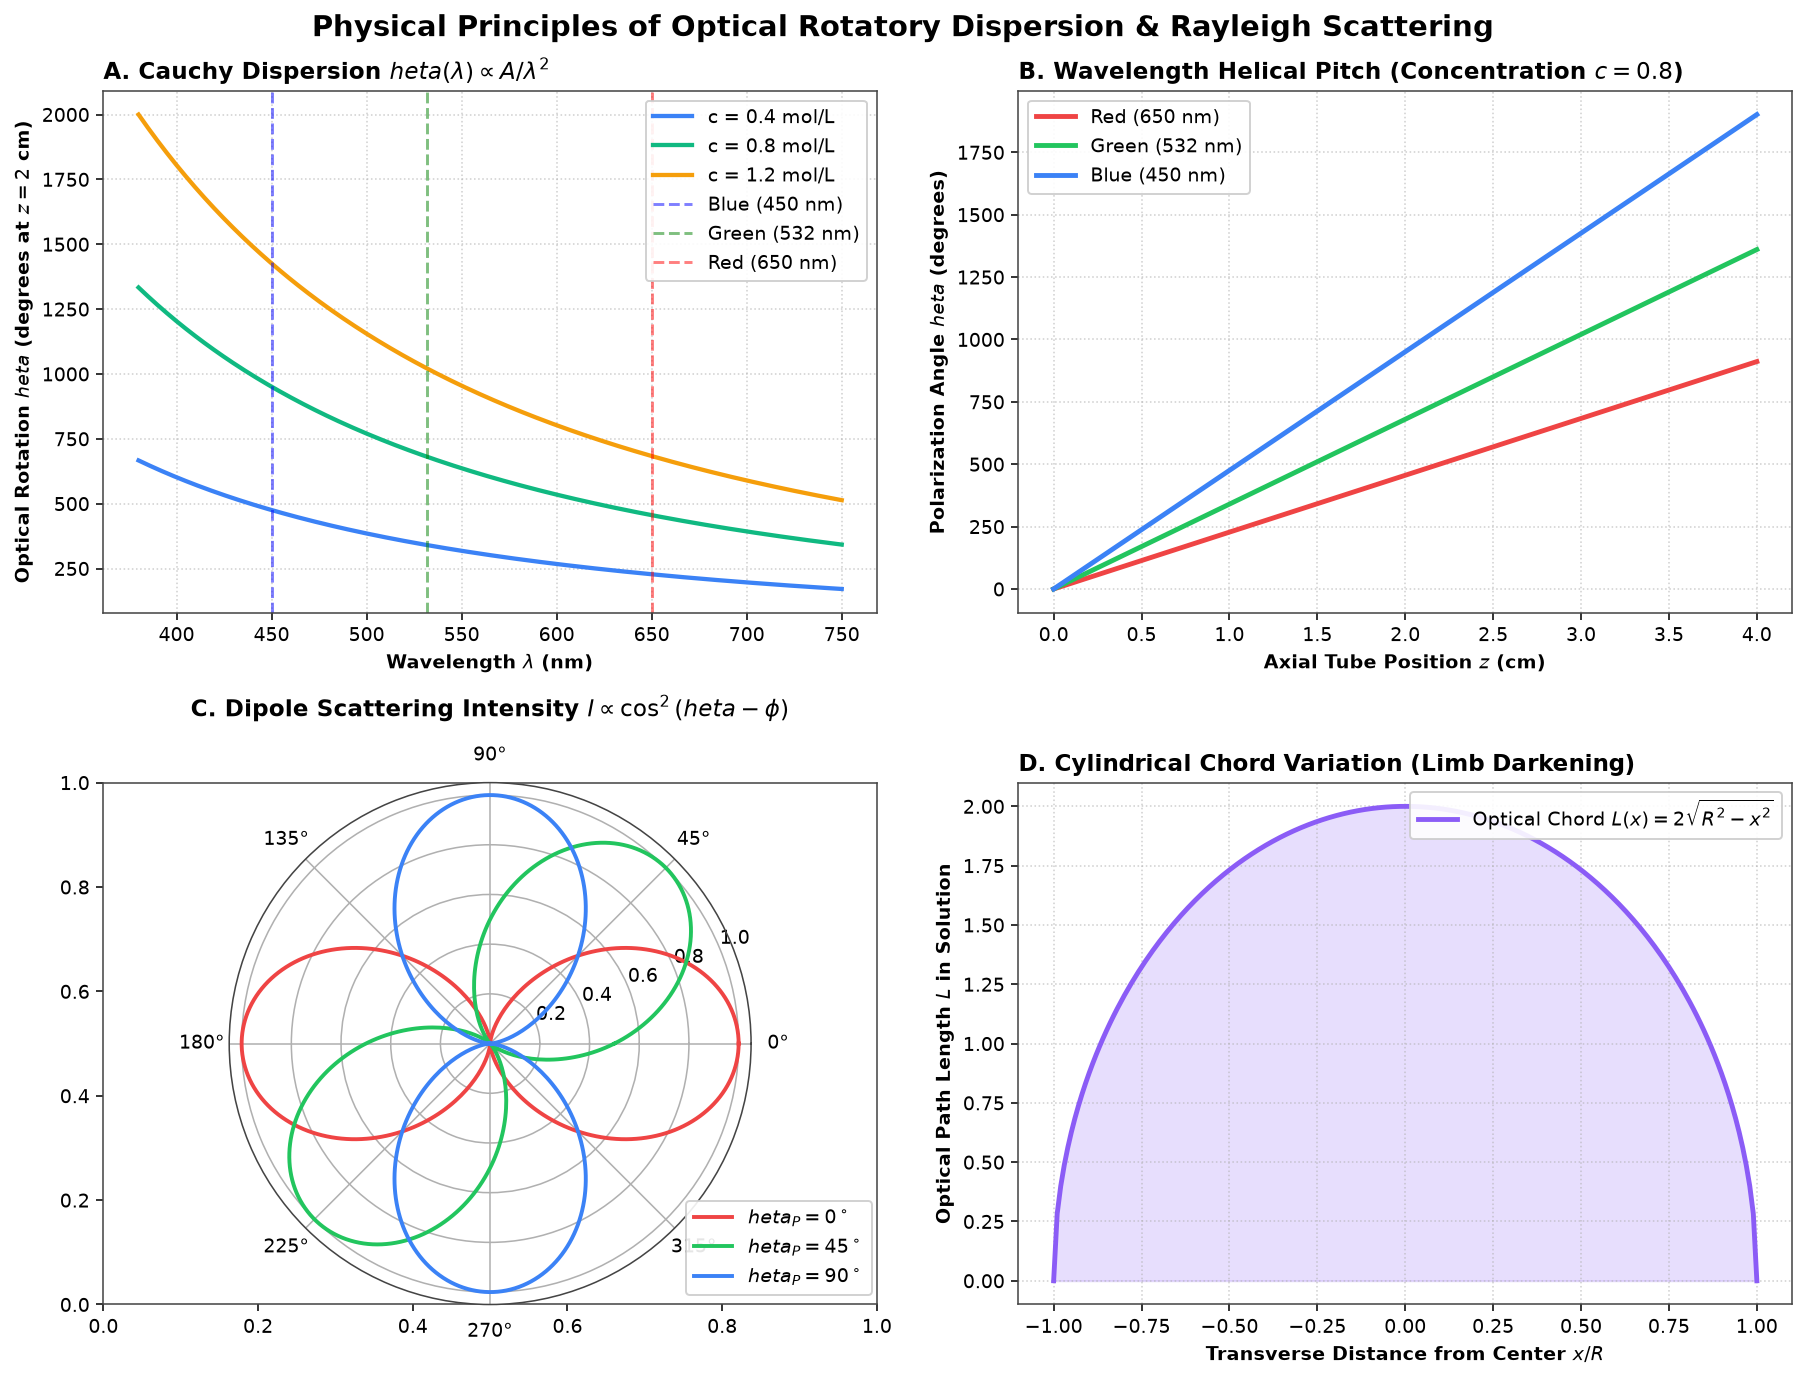

In [4]:
# ===========================================================================
# 5. Diagnostic Physics: Cauchy Dispersion & Rayleigh Polarimetry
# ===========================================================================

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
fig.suptitle("Physical Principles of Optical Rotatory Dispersion & Rayleigh Scattering", fontsize=15, fontweight='bold', y=0.98)

# Panel A: Cauchy Dispersion Curve theta(lambda)
ax1 = axes[0, 0]
lambda_range = np.linspace(380, 750, 300)
for c, color, label in [(0.4, '#3b82f6', 'c = 0.4 mol/L'),
                        (0.8, '#10b981', 'c = 0.8 mol/L'),
                        (1.2, '#f59e0b', 'c = 1.2 mol/L')]:
    rot_deg = np.degrees(cauchy_rotation(lambda_range, z=2.0, concentration=c, theta0_rad=0))
    ax1.plot(lambda_range, rot_deg, color=color, lw=2.2, label=label)

ax1.axvline(LAMBDA_BLUE, color='blue', linestyle='--', alpha=0.5, label='Blue (450 nm)')
ax1.axvline(LAMBDA_GREEN, color='green', linestyle='--', alpha=0.5, label='Green (532 nm)')
ax1.axvline(LAMBDA_RED, color='red', linestyle='--', alpha=0.5, label='Red (650 nm)')
ax1.set_xlabel("Wavelength $\lambda$ (nm)", fontweight='bold')
ax1.set_ylabel("Optical Rotation $\theta$ (degrees at $z = 2$ cm)", fontweight='bold')
ax1.set_title("A. Cauchy Dispersion $\theta(\lambda) \propto A / \lambda^2$", fontweight='bold', loc='left')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper right', framealpha=0.9)

# Panel B: Rotation vs Depth z for RGB Channels
ax2 = axes[0, 1]
z_range = np.linspace(0, 4, 300)
c_fixed = 0.8
rot_r = np.degrees(cauchy_rotation(LAMBDA_RED, z_range, c_fixed, 0))
rot_g = np.degrees(cauchy_rotation(LAMBDA_GREEN, z_range, c_fixed, 0))
rot_b = np.degrees(cauchy_rotation(LAMBDA_BLUE, z_range, c_fixed, 0))

ax2.plot(z_range, rot_r, color='#ef4444', lw=2.5, label=f'Red ({LAMBDA_RED:.0f} nm)')
ax2.plot(z_range, rot_g, color='#22c55e', lw=2.5, label=f'Green ({LAMBDA_GREEN:.0f} nm)')
ax2.plot(z_range, rot_b, color='#3b82f6', lw=2.5, label=f'Blue ({LAMBDA_BLUE:.0f} nm)')
ax2.set_xlabel("Axial Tube Position $z$ (cm)", fontweight='bold')
ax2.set_ylabel("Polarization Angle $\theta$ (degrees)", fontweight='bold')
ax2.set_title(f"B. Wavelength Helical Pitch (Concentration $c = {c_fixed}$)", fontweight='bold', loc='left')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='upper left', framealpha=0.9)

# Panel C: Rayleigh Dipole Radiation Pattern (Polar Plot)
ax3 = plt.subplot(2, 2, 3, projection='polar')
phi = np.linspace(0, 2*np.pi, 360)
for theta_pol, col, name in [(0, '#ef4444', '$\theta_P = 0^\circ$'),
                             (np.pi/4, '#22c55e', '$\theta_P = 45^\circ$'),
                             (np.pi/2, '#3b82f6', '$\theta_P = 90^\circ$')]:
    intensity = np.cos(phi - theta_pol) ** 2
    ax3.plot(phi, intensity, color=col, lw=2.0, label=name)
ax3.set_title("C. Dipole Scattering Intensity $I \propto \cos^2(\theta - \phi)$", fontweight='bold', pad=15)
ax3.legend(loc='lower right', bbox_to_anchor=(1.25, 0.0), framealpha=0.9)

# Panel D: Cylindrical Optical Path Length L(x)
ax4 = axes[1, 1]
x_coords = np.linspace(-1.0, 1.0, 200)
chord = 2.0 * np.sqrt(1.0 - x_coords**2)
ax4.plot(x_coords, chord, color='#8b5cf6', lw=2.5, label='Optical Chord $L(x) = 2\sqrt{R^2 - x^2}$')
ax4.fill_between(x_coords, 0, chord, color='#8b5cf6', alpha=0.2)
ax4.set_xlabel("Transverse Distance from Center $x/R$", fontweight='bold')
ax4.set_ylabel("Optical Path Length $L$ in Solution", fontweight='bold')
ax4.set_title("D. Cylindrical Chord Variation (Limb Darkening)", fontweight='bold', loc='left')
ax4.grid(True, linestyle=':', alpha=0.6)
ax4.legend(loc='upper right', framealpha=0.9)

plt.tight_layout()
plt.show()


Rendering high-resolution comparison (Discrete RGB vs Continuous Spectrum)...


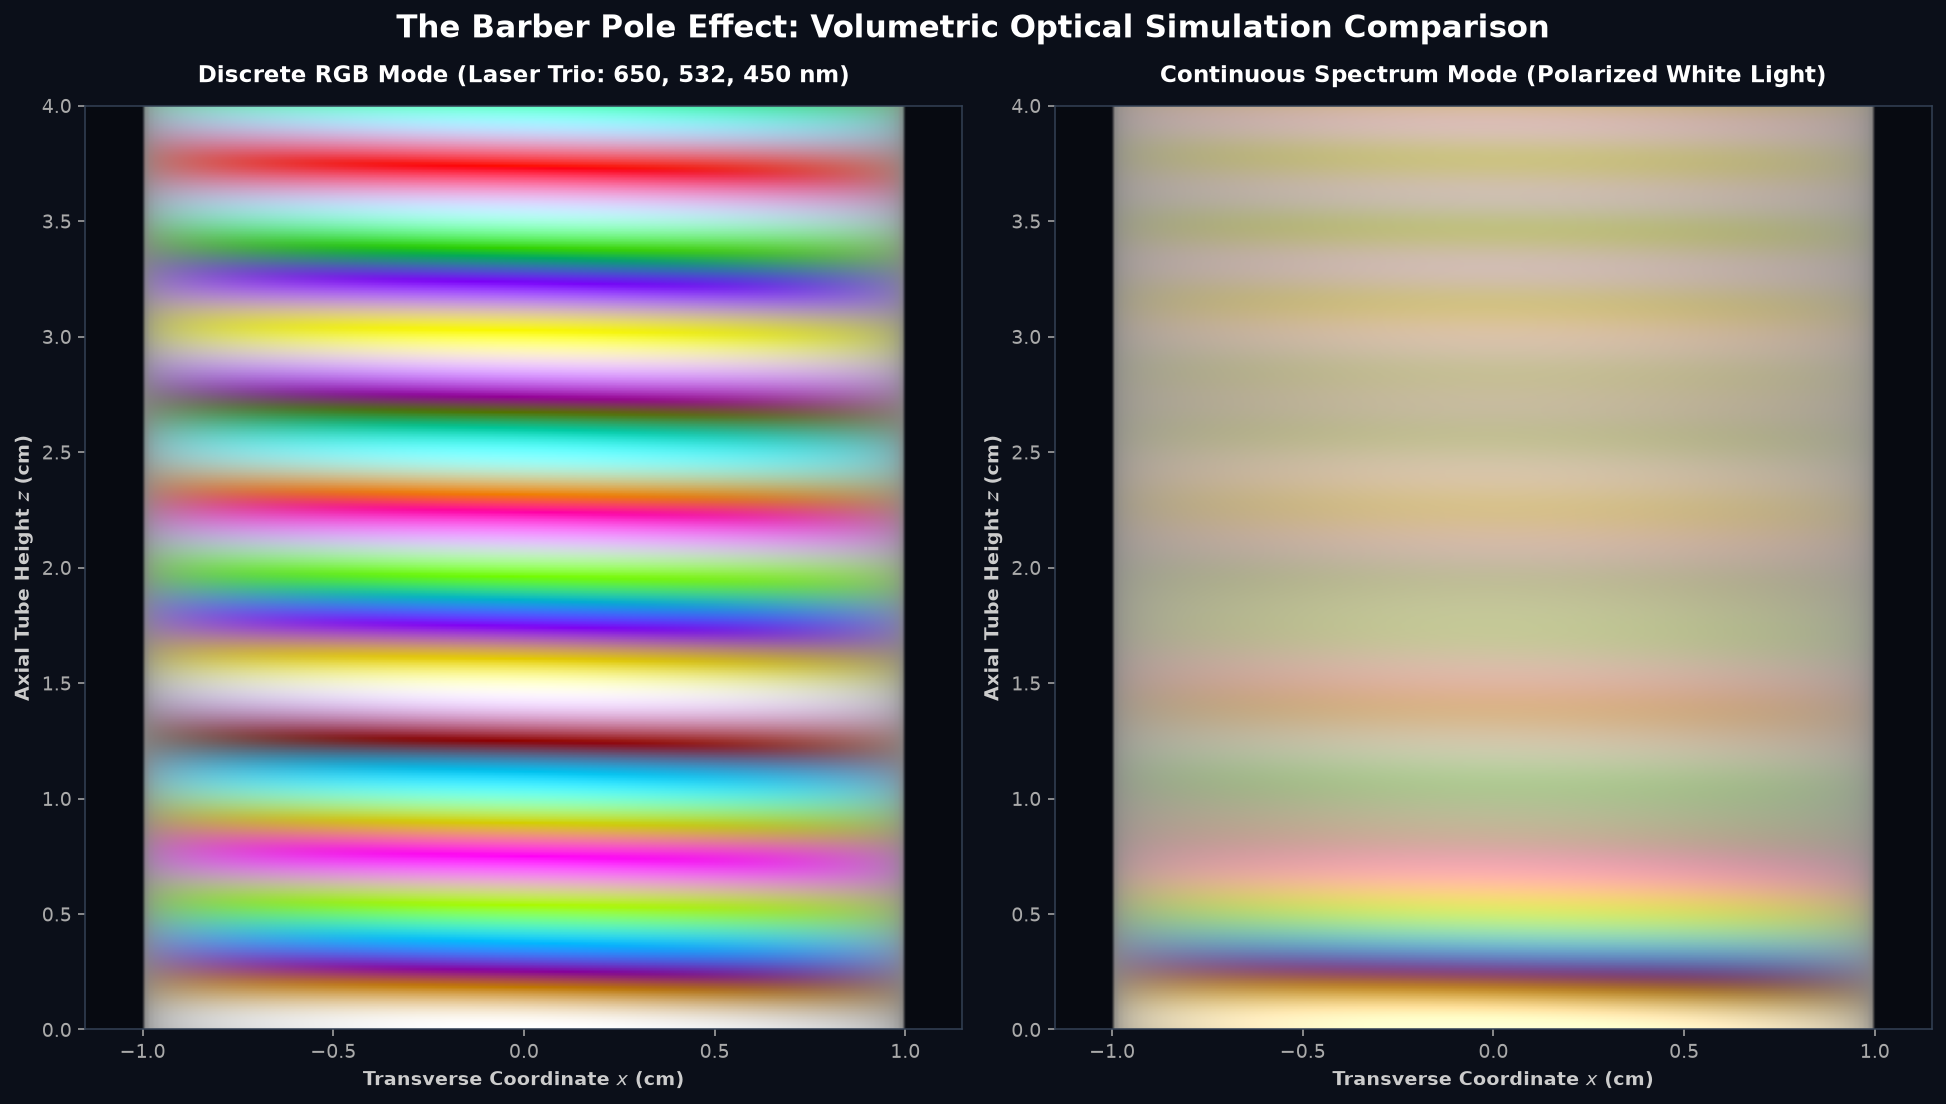

In [5]:
# ===========================================================================
# 6. High-Resolution Simulation: Discrete RGB vs Continuous Spectrum
# ===========================================================================

print("Rendering high-resolution comparison (Discrete RGB vs Continuous Spectrum)...")

img_rgb_bands = simulate_barber_pole(
    concentration=0.85,
    theta0_deg=0.0,
    filter2_deg=None,
    mode='rgb',
    tube_radius=1.0,
    tube_height=4.0,
    resolution=(360, 180)
)

img_spectrum = simulate_barber_pole(
    concentration=0.85,
    theta0_deg=0.0,
    filter2_deg=None,
    mode='spectrum',
    tube_radius=1.0,
    tube_height=4.0,
    resolution=(360, 180)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 8), facecolor='#0b0f19')

# Left Panel: Discrete RGB
ax1 = axes[0]
ax1.imshow(img_rgb_bands, extent=[-1.15, 1.15, 0, 4.0], origin='lower', aspect='auto')
ax1.set_title("Discrete RGB Mode (Laser Trio: 650, 532, 450 nm)", color='white', fontsize=12, fontweight='bold', pad=12)
ax1.set_xlabel("Transverse Coordinate $x$ (cm)", color='#cccccc', fontweight='bold')
ax1.set_ylabel("Axial Tube Height $z$ (cm)", color='#cccccc', fontweight='bold')
ax1.tick_params(colors='#aaaaaa')
for spine in ax1.spines.values():
    spine.set_color('#334155')

# Right Panel: Continuous Spectrum
ax2 = axes[1]
ax2.imshow(img_spectrum, extent=[-1.15, 1.15, 0, 4.0], origin='lower', aspect='auto')
ax2.set_title("Continuous Spectrum Mode (Polarized White Light)", color='white', fontsize=12, fontweight='bold', pad=12)
ax2.set_xlabel("Transverse Coordinate $x$ (cm)", color='#cccccc', fontweight='bold')
ax2.set_ylabel("Axial Tube Height $z$ (cm)", color='#cccccc', fontweight='bold')
ax2.tick_params(colors='#aaaaaa')
for spine in ax2.spines.values():
    spine.set_color('#334155')

fig.suptitle("The Barber Pole Effect: Volumetric Optical Simulation Comparison", color='white', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


---
## 7. Interactive Simulation Dashboard

Use the interactive controls below to explore the physical parameters in real time:

1. **Concentration ($c$):** Controls the density of chiral sugar molecules in solution. Higher concentration increases the specific rotation rate $\frac{d\theta}{dz}$, wrapping the diagonal helical stripes more tightly.
2. **Initial Polarizer ($\theta_0$):** Rotates the input polarizer at the entrance of the tube ($z = 0$). **Rotating this slider causes the diagonal stripes to "walk" longitudinally along the tube**, directly recreating the famous physical optical illusion!
3. **Exit Polarizer ($\theta_2$):** Simulates viewing through an analyzer filter at the exit of the tube, demonstrating Malus's Law attenuation.
4. **Spectrum Mode:** Toggle between discrete RGB laser wavelengths and full continuous white light spectrum.


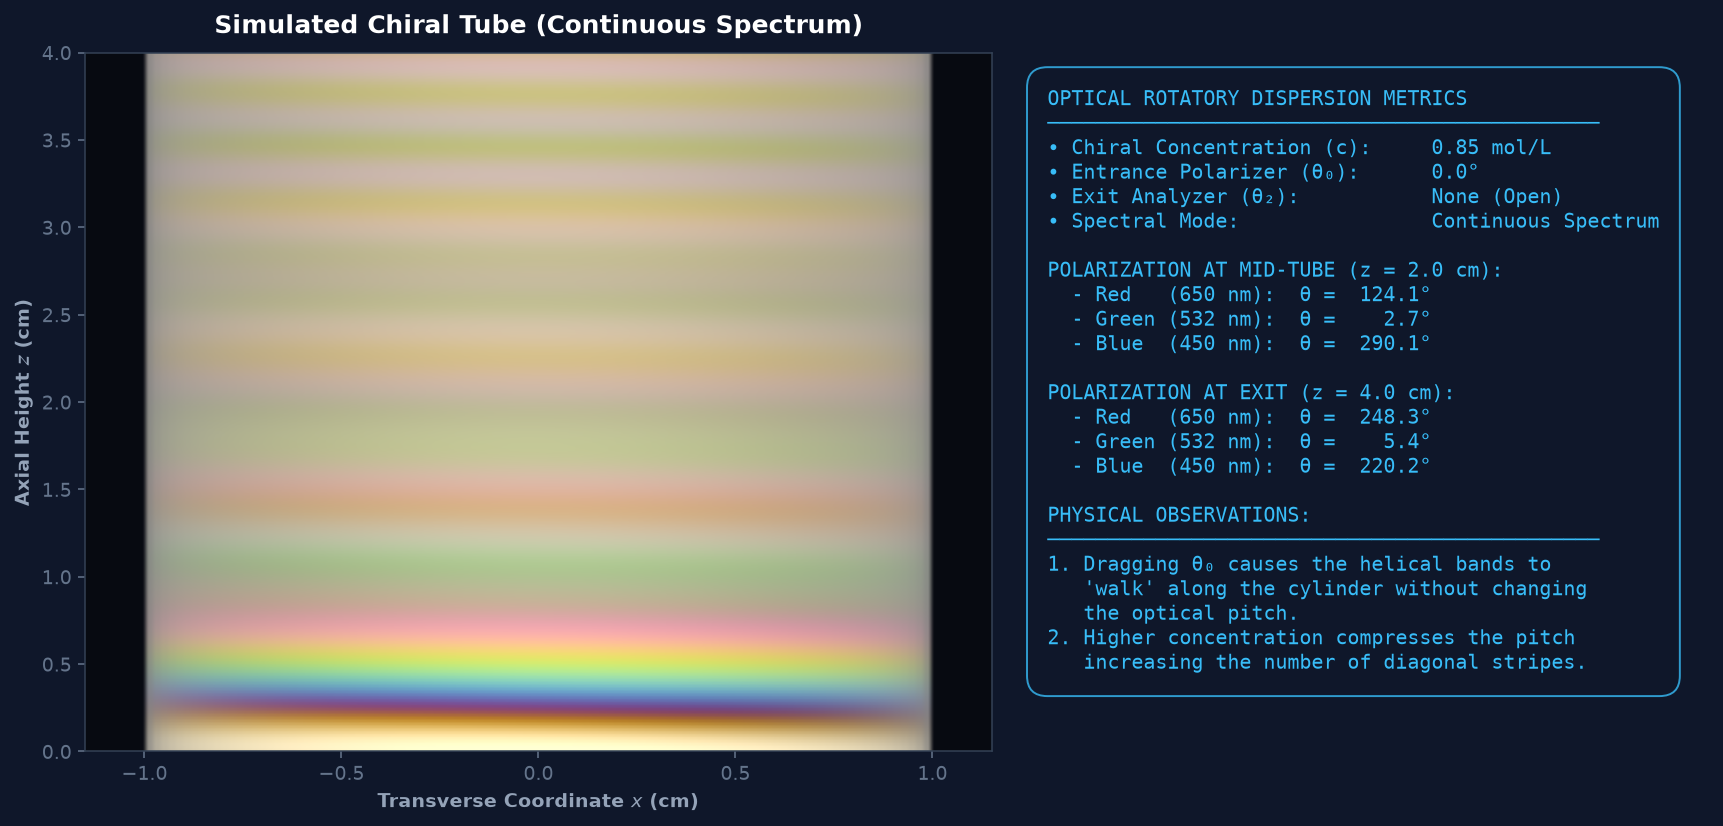

interactive(children=(FloatSlider(value=0.85, description='Concentration (c):', layout=Layout(width='600px'), …

In [6]:
# ===========================================================================
# 8. Live Interactive Simulation Dashboard (ipywidgets)
# ===========================================================================

def interactive_barber_pole(concentration=0.85, theta0=0, filter2_enabled=False, filter2_angle=0, mode='Continuous Spectrum'):
    f2_val = filter2_angle if filter2_enabled else None
    sim_mode = 'spectrum' if 'Continuous' in mode else 'rgb'
    
    # Run raymarch simulation
    sim_img = simulate_barber_pole(
        concentration=concentration,
        theta0_deg=theta0,
        filter2_deg=f2_val,
        mode=sim_mode,
        tube_radius=1.0,
        tube_height=4.0,
        resolution=(240, 120),
        n_depth_steps=24
    )
    
    fig, (ax_tube, ax_info) = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={'width_ratios': [1.3, 1]}, facecolor='#0f172a')
    
    # Render simulated tube
    ax_tube.imshow(sim_img, extent=[-1.15, 1.15, 0, 4.0], origin='lower', aspect='auto')
    ax_tube.set_title(f"Simulated Chiral Tube ({mode})", color='white', fontweight='bold', fontsize=13, pad=10)
    ax_tube.set_xlabel("Transverse Coordinate $x$ (cm)", color='#94a3b8', fontweight='bold')
    ax_tube.set_ylabel("Axial Height $z$ (cm)", color='#94a3b8', fontweight='bold')
    ax_tube.tick_params(colors='#64748b')
    for s in ax_tube.spines.values():
        s.set_color('#334155')

    # Information & Polarization Metrics Panel
    ax_info.set_facecolor('#1e293b')
    ax_info.axis('off')
    
    # Compute live rotation angles at midpoint (z = 2.0 cm) and exit (z = 4.0 cm)
    theta_r_mid = np.degrees(cauchy_rotation(LAMBDA_RED, 2.0, concentration, np.radians(theta0))) % 360
    theta_g_mid = np.degrees(cauchy_rotation(LAMBDA_GREEN, 2.0, concentration, np.radians(theta0))) % 360
    theta_b_mid = np.degrees(cauchy_rotation(LAMBDA_BLUE, 2.0, concentration, np.radians(theta0))) % 360
    
    theta_r_exit = np.degrees(cauchy_rotation(LAMBDA_RED, 4.0, concentration, np.radians(theta0))) % 360
    theta_g_exit = np.degrees(cauchy_rotation(LAMBDA_GREEN, 4.0, concentration, np.radians(theta0))) % 360
    theta_b_exit = np.degrees(cauchy_rotation(LAMBDA_BLUE, 4.0, concentration, np.radians(theta0))) % 360

    info_text = (
        "OPTICAL ROTATORY DISPERSION METRICS\n"
        "──────────────────────────────────────────────\n"
        f"• Chiral Concentration (c):     {concentration:.2f} mol/L\n"
        f"• Entrance Polarizer (θ₀):      {theta0:.1f}°\n"
        f"• Exit Analyzer (θ₂):           {f'{filter2_angle:.1f}°' if filter2_enabled else 'None (Open)'}\n"
        f"• Spectral Mode:                {mode}\n\n"
        "POLARIZATION AT MID-TUBE (z = 2.0 cm):\n"
        f"  - Red   (650 nm):  θ = {theta_r_mid:6.1f}°\n"
        f"  - Green (532 nm):  θ = {theta_g_mid:6.1f}°\n"
        f"  - Blue  (450 nm):  θ = {theta_b_mid:6.1f}°\n\n"
        "POLARIZATION AT EXIT (z = 4.0 cm):\n"
        f"  - Red   (650 nm):  θ = {theta_r_exit:6.1f}°\n"
        f"  - Green (532 nm):  θ = {theta_g_exit:6.1f}°\n"
        f"  - Blue  (450 nm):  θ = {theta_b_exit:6.1f}°\n\n"
        "PHYSICAL OBSERVATIONS:\n"
        "──────────────────────────────────────────────\n"
        "1. Dragging θ₀ causes the helical bands to\n"
        "   'walk' along the cylinder without changing\n"
        "   the optical pitch.\n"
        "2. Higher concentration compresses the pitch\n"
        "   increasing the number of diagonal stripes."
    )
    
    ax_info.text(0.05, 0.95, info_text, transform=ax_info.transAxes,
                 fontsize=10.5, fontfamily='monospace', color='#38bdf8',
                 verticalalignment='top', bbox=dict(boxstyle='round,pad=1', facecolor='#0f172a', edgecolor='#38bdf8', alpha=0.8))

    plt.tight_layout()
    plt.show()

# Render default view
interactive_barber_pole()

# Display interactive controls
widgets.interact(
    interactive_barber_pole,
    concentration=widgets.FloatSlider(value=0.85, min=0.1, max=2.0, step=0.05, description='Concentration (c):', style={'description_width': 'initial'}, layout=widgets.Layout(width='600px')),
    theta0=widgets.IntSlider(value=0, min=0, max=360, step=5, description='Initial Polarizer (θ₀):', style={'description_width': 'initial'}, layout=widgets.Layout(width='600px')),
    filter2_enabled=widgets.Checkbox(value=False, description='Enable Exit Polarizer (θ₂)', style={'description_width': 'initial'}),
    filter2_angle=widgets.IntSlider(value=0, min=0, max=360, step=5, description='Exit Polarizer Angle:', style={'description_width': 'initial'}, layout=widgets.Layout(width='600px')),
    mode=widgets.Dropdown(options=['Continuous Spectrum (White Light)', 'Discrete RGB Bands (Laser Trio)'], value='Continuous Spectrum (White Light)', description='Spectrum Mode:', style={'description_width': 'initial'})
);


---
## 9. 3D Trajectory of the Polarization Helix

Inside the cylindrical tube, the electric field vector $\vec{E}(z)$ of linearly polarized light does not remain in a fixed plane; its tip traces out a **spatial 3D helix** as it travels in the $+z$ direction:
$$\vec{E}(z, \lambda) = E_0 \begin{pmatrix} \cos\theta(z, \lambda) \\ \sin\theta(z, \lambda) \\ 0 \end{pmatrix}$$

The spatial pitch $\mathcal{P}$ of the helix (the axial distance required for a full $2\pi$ rotation) is directly proportional to $\lambda^2$:
$$\mathcal{P}(\lambda) = \frac{2\pi}{\alpha(\lambda) \cdot c} = \frac{2\pi \lambda^2}{A \cdot c}$$

The interactive 3D plot below renders the helical polarization vector trajectories for Red, Green, and Blue light propagating up the sugar water tube.


In [7]:
# ===========================================================================
# 10. Interactive 3D Visualization of the Polarization Helix (Plotly)
# ===========================================================================
import plotly.graph_objects as go

def create_3d_helix_plot(concentration=0.85, theta0_deg=0):
    theta0_rad = np.radians(theta0_deg)
    z_vals = np.linspace(0, 4.0, 500)
    tube_radius = 1.0

    # Calculate 3D trajectories
    theta_r = cauchy_rotation(LAMBDA_RED, z_vals, concentration, theta0_rad)
    theta_g = cauchy_rotation(LAMBDA_GREEN, z_vals, concentration, theta0_rad)
    theta_b = cauchy_rotation(LAMBDA_BLUE, z_vals, concentration, theta0_rad)

    x_r, y_r = 0.85 * np.cos(theta_r), 0.85 * np.sin(theta_r)
    x_g, y_g = 0.85 * np.cos(theta_g), 0.85 * np.sin(theta_g)
    x_b, y_b = 0.85 * np.cos(theta_b), 0.85 * np.sin(theta_b)

    fig = go.Figure()

    # 1. Cylinder Boundary Surface
    theta_cyl = np.linspace(0, 2*np.pi, 60)
    z_cyl = np.linspace(0, 4.0, 20)
    THETA_CYL, Z_CYL = np.meshgrid(theta_cyl, z_cyl)
    X_CYL = tube_radius * np.cos(THETA_CYL)
    Y_CYL = tube_radius * np.sin(THETA_CYL)

    fig.add_trace(go.Surface(
        x=X_CYL, y=Y_CYL, z=Z_CYL,
        opacity=0.15,
        colorscale=[[0, '#60a5fa'], [1, '#93c5fd']],
        showscale=False,
        name='Glass Tube'
    ))

    # 2. Central Optical Axis
    fig.add_trace(go.Scatter3d(
        x=[0, 0], y=[0, 0], z=[0, 4.0],
        mode='lines',
        line=dict(color='white', width=3, dash='dash'),
        name='Optical Axis (z)'
    ))

    # 3. Polarization Helices
    fig.add_trace(go.Scatter3d(
        x=x_r, y=y_r, z=z_vals,
        mode='lines',
        line=dict(color='#ef4444', width=6),
        name=f'Red ({LAMBDA_RED:.0f} nm)'
    ))

    fig.add_trace(go.Scatter3d(
        x=x_g, y=y_g, z=z_vals,
        mode='lines',
        line=dict(color='#22c55e', width=6),
        name=f'Green ({LAMBDA_GREEN:.0f} nm)'
    ))

    fig.add_trace(go.Scatter3d(
        x=x_b, y=y_b, z=z_vals,
        mode='lines',
        line=dict(color='#3b82f6', width=6),
        name=f'Blue ({LAMBDA_BLUE:.0f} nm)'
    ))

    # Layout styling
    fig.update_layout(
        title=dict(
            text=f"<b>3D Polarization Helices inside Chiral Tube</b> (c = {concentration} mol/L, θ₀ = {theta0_deg}°)",
            font=dict(color='white', size=16)
        ),
        paper_bgcolor='#0f172a',
        scene=dict(
            xaxis=dict(title='X', backgroundcolor='#0f172a', gridcolor='#334155', range=[-1.3, 1.3]),
            yaxis=dict(title='Y', backgroundcolor='#0f172a', gridcolor='#334155', range=[-1.3, 1.3]),
            zaxis=dict(title='Z (Optical Path)', backgroundcolor='#0f172a', gridcolor='#334155', range=[0, 4.2]),
            camera=dict(eye=dict(x=1.8, y=1.8, z=1.2))
        ),
        legend=dict(font=dict(color='white'), bgcolor='rgba(15, 23, 42, 0.7)'),
        margin=dict(l=0, r=0, b=0, t=40),
        height=620
    )

    return fig

fig_3d = create_3d_helix_plot(concentration=0.85, theta0_deg=0)
fig_3d.show()


In [8]:
# ===========================================================================
# 11. Animated Demonstration: The "Walking" Barber Pole Effect
# ===========================================================================
# Demonstrates continuous rotation of the entrance polarizer theta_0
from matplotlib.animation import FuncAnimation

fig, ax = plt.subplots(figsize=(6, 8), facecolor='#0b0f19')

# Precompute initial frame
init_img = simulate_barber_pole(concentration=0.85, theta0_deg=0, mode='spectrum', resolution=(180, 90), n_depth_steps=16)
im = ax.imshow(init_img, extent=[-1.15, 1.15, 0, 4.0], origin='lower', aspect='auto')

title_text = ax.set_title("Entrance Polarizer θ₀ = 0°\n(Watch the stripes walk!)",
                          color='white', fontsize=12, fontweight='bold', pad=10)
ax.set_xlabel("Transverse Coordinate x (cm)", color='#cccccc', fontweight='bold')
ax.set_ylabel("Axial Tube Height z (cm)", color='#cccccc', fontweight='bold')
ax.tick_params(colors='#aaaaaa')
for spine in ax.spines.values():
    spine.set_color('#334155')

def animate(frame):
    angle = frame * 15  # 0 to 360 degrees
    updated_img = simulate_barber_pole(
        concentration=0.85,
        theta0_deg=angle,
        mode='spectrum',
        resolution=(180, 90),
        n_depth_steps=16
    )
    im.set_data(updated_img)
    title_text.set_text(f"Entrance Polarizer θ₀ = {angle}°\n(Watch the stripes walk!)")
    return [im, title_text]

anim = FuncAnimation(fig, animate, frames=24, interval=120, blit=True)
plt.close(fig)  # Prevent static display

# Render HTML5 video animation directly in notebook
display(HTML(anim.to_jshtml()))


---
## 12. University Presentation Summary & Conclusions

### Key Physical Takeaways
1. **Dispersion Drives the Barber Pole:**  
   Without optical dispersion ($\frac{d\theta}{d\lambda} \neq 0$), white light would rotate as a single monochromatic polarization, producing only monochrome brightness variations. The chromatic Cauchy relation $\theta \propto \lambda^{-2}$ separates red, green, and blue into different helical pitches, producing the colorful helical bands.

2. **Dipole Radiation Enables Lateral Observation:**  
   The solution itself functions as a built-in polarimeter. Rayleigh scattering from oscillating dipoles naturally selects and filters polarization components according to $I \propto \cos^2(\theta - \phi)$, making the internal polarization state visible from the side.

3. **Geometry Maps 3D Helices to 2D Diagonals:**  
   The diagonal tilt of the stripes is an optical path length and perspective effect resulting from integration through the curved cylindrical surface ($L(x) = 2\sqrt{R^2 - x^2}$).

4. **The "Walking" Illusion:**  
   Rotating the initial polarizing filter changes the boundary phase $\theta_0$ without altering the helical pitch $\mathcal{P}$. This spatial phase shift causes the bands to translate along the length of the cylinder—the optical equivalent of Archimedes' screw or a spinning barber's pole.

---

### Academic References
* **Biot, J. B. (1815):** *Phénomène de polarisation rotatoire.* Mémoires de l'Académie des Sciences.
* **Cauchy, A. L. (1836):** *Mémoire sur la dispersion de la lumière.* Nouveaux Exercices de Mathématiques.
* **Hecht, E. (2017):** *Optics (5th Edition)*, Chapter 8: Polarization and Optical Activity. Pearson.
* **Grant Sanderson (3Blue1Brown):** *Optical Rotatory Dispersion & The Barber Pole Effect*.
* **Fresnel, A. (1822):** *De la lumière polarisée et de la polarisation circulaire.* Annales de Chimie et de Physique.

---
*Created by Kartik Khare*
